# 균형 이원분산분석

`balanced_two_way.csv`의 18행을 사용합니다. 각 행은 독립 관측 1개이며, `method`와 `setting`의 6개 조합마다 관측값이 3개씩 있습니다.

`response`를 반응변수로 두고, `method`와 `setting`을 범주형 고정요인으로 처리합니다. 두 주효과와 교호작용을 포함한 최소제곱 모형에 합 대비를 적용하고, Type II 제곱합으로 검정합니다. 입력 데이터에 변환, 집계 또는 제외를 적용하지 않습니다.

### 다시 실행하기

CSV를 노트북과 같은 폴더에 둡니다. Python 3 Jupyter 커널에서 필요한 패키지를 설치한 후 모든 셀을 위에서부터 실행합니다. 아래 명령은 패키지 설치가 필요한 경우에 실행합니다.

```python
%pip install numpy pandas scipy statsmodels matplotlib jinja2
```


In [1]:
"""Reusable Matplotlib appearance for the user's report figures.

No data, model, axis limits, or backend is selected by this module.
Requires matplotlib. Apply appearance after any other library theme.
"""
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


COLORS = {
    "ink": "#263746",
    "muted": "#647482",
    "grid": "#DCE3E8",
    "data": "#4C78A8",
    "secondary": "#54A28B",
    "threshold": "#C7774E",
}
SCATTER_KW = {"s": 49, "marker": "o", "color": COLORS["data"], "zorder": 4}
FIT_LINE_KW = {"color": COLORS["data"], "linewidth": 2, "linestyle": ":", "zorder": 3}
REFERENCE_LINE_KW = {
    "color": COLORS["threshold"], "linewidth": 1.2, "linestyle": ":", "zorder": 2,
}
LAYOUTS = {
    "single": {
        "shape": (1, 1), "figsize": (9, 5.8), "caption_y": 0.055,
        "adjust": {"left": 0.12, "right": 0.98, "top": 0.92, "bottom": 0.22},
    },
    "horizontal": {
        "shape": (1, 2), "figsize": (14, 5.8), "caption_y": 0.055,
        "adjust": {"left": 0.07, "right": 0.98, "top": 0.88, "bottom": 0.22, "wspace": 0.18},
    },
    "vertical": {
        "shape": (2, 1), "figsize": (9, 10.8), "caption_y": 0.035,
        "adjust": {"left": 0.12, "right": 0.98, "top": 0.94, "bottom": 0.12, "hspace": 0.38},
    },
}


def apply_style():
    """Apply shared typography and palette without changing the backend."""
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"],
        "font.size": 11,
        "axes.labelcolor": COLORS["ink"],
        "axes.edgecolor": COLORS["grid"],
        "axes.labelpad": 9,
        "axes.titlesize": 13,
        "axes.titleweight": "bold",
        "axes.titlepad": 13,
        "xtick.color": COLORS["muted"],
        "ytick.color": COLORS["muted"],
        "text.color": COLORS["ink"],
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.dpi": 300,
        "legend.frameon": False,
        "legend.fontsize": 9,
    })


def make_figure(layout="single", *, sharex=False, sharey=False):
    """Return (figure, axes) using a single, horizontal, or vertical preset."""
    config = LAYOUTS[layout]
    apply_style()
    fig, axes = plt.subplots(*config["shape"], figsize=config["figsize"],
                             sharex=sharex, sharey=sharey)
    fig.subplots_adjust(**config["adjust"])
    return fig, axes


def style_axes(ax, *, x_label=None, y_label=None, grid_axis="both",
               percent_axis=None, percent_xmax=100, percent_decimals=0,
               show_x_tick_labels=None):
    """Format axes without changing data limits or tick positions.

    percent_axis: None, 'x', 'y', or 'both'. percent_xmax is the value
    representing 100% (100 for percentages, 1 for proportions).
    grid_axis: None (no grid), 'x', 'y', or 'both'.
    """
    if percent_axis not in (None, "x", "y", "both"):
        raise ValueError("percent_axis must be None, 'x', 'y', or 'both'")
    if percent_axis is not None and percent_xmax <= 0:
        raise ValueError("percent_xmax must be positive")
    if grid_axis not in (None, "x", "y", "both"):
        raise ValueError("grid_axis must be None, 'x', 'y', or 'both'")
    if x_label is not None:
        ax.set_xlabel(x_label, labelpad=9)
    if y_label is not None:
        ax.set_ylabel(y_label, labelpad=9)
    for name in ("x", "y"):
        if percent_axis in (name, "both"):
            getattr(ax, name + "axis").set_major_formatter(
                PercentFormatter(xmax=percent_xmax, decimals=percent_decimals)
            )
    ax.grid(False, which="both", axis="both")
    if grid_axis is not None:
        ax.grid(axis=grid_axis, color=COLORS["grid"], linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    for name in ("left", "bottom"):
        ax.spines[name].set_color(COLORS["grid"])
    ax.tick_params(axis="both", which="both", length=0, colors=COLORS["muted"], pad=7)
    if show_x_tick_labels is not None:
        ax.tick_params(axis="x", labelbottom=show_x_tick_labels)


def add_caption(fig, text, *, layout="single", y=None):
    """Add a centered bottom caption; margins come from make_figure()."""
    return fig.text(0.5, LAYOUTS[layout]["caption_y"] if y is None else y,
                    text, ha="center", fontsize=12, fontweight="bold",
                    color=COLORS["ink"])


def save_figure(fig, path, *, dpi=300):
    """Save a figure at the explicit output path and return its absolute path."""
    path = Path(path).resolve()
    fig.savefig(path, dpi=dpi, bbox_inches="tight", facecolor="white")
    return path

from io import BytesIO
from itertools import combinations

from IPython.display import Image, display
from matplotlib import font_manager
from matplotlib.textpath import TextToPath
import numpy as np
import pandas as pd
from scipy.stats import probplot
from statsmodels.api import stats
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests

## 1. 입력 및 분석 설정

In [2]:
data_csv = 'balanced_two_way.csv'
encoding = 'utf-8-sig'
design = {'response': 'response',
 'factors': ['method', 'setting'],
 'interaction': True,
 'ss_type': 2,
 'contrast': 'sum'}

## 2. 데이터 불러오기

In [3]:
data = pd.read_csv(Path(data_csv), encoding=encoding)

## 3. 입력 검증 및 모형 적합

In [4]:
response = design['response']
factors = design['factors']
block = design.get('block')
source_columns = [response, *factors, *([block] if block else [])]
missing = set(source_columns) - set(data.columns)
if missing:
    raise ValueError(f'Missing columns: {sorted(missing)}')
if data.empty or data[source_columns].isna().any().any():
    raise ValueError('Selected analysis columns require observations with no missing values.')

# Map original CSV labels to formula-safe names.
factor_ids = [f'factor_{i}' for i in range(1, len(factors) + 1)]
group_ids = factor_ids + (['block_id'] if block else [])
fit_data = data[source_columns].copy()
fit_data.columns = ['y', *group_ids]
fit_data['y'] = pd.to_numeric(fit_data['y'], errors='raise').astype(float)
if not np.isfinite(fit_data['y']).all() or fit_data['y'].nunique() < 2:
    raise ValueError('The response must have finite numeric values and some variation.')
for column in group_ids:
    if fit_data[column].nunique() < 2:
        raise ValueError(f'{source_columns[fit_data.columns.get_loc(column)]!r} needs at least two levels.')
    fit_data[column] = fit_data[column].astype('category')

counts = fit_data.groupby(group_ids, observed=False).size()
if block and not counts.eq(1).all():
    raise ValueError('The fixed-block design needs one observation per block–factor combination.')
if len(factors) == 2 and not block and (counts.min() < 1 or counts.nunique() != 1):
    raise ValueError('The two-way design needs complete cells with equal sample sizes.')

contrast = {'sum': 'Sum', 'treatment': 'Treatment'}[design['contrast']]
factor_terms = [f'C({term}, {contrast})' for term in factor_ids]
interaction = design.get('interaction', False)
formula_rhs = (' * ' if interaction else ' + ').join(factor_terms)
block_term = f'C(block_id, {contrast})'
if block:
    formula_rhs = (f'{block_term} + {formula_rhs}' if design.get('block_first')
                   else f'{formula_rhs} + {block_term}')
model = ols(f'y ~ {formula_rhs}', data=fit_data, missing='raise').fit()
if model.df_resid <= 0 or model.model.rank != model.model.exog.shape[1]:
    raise ValueError('The design requires a full-rank model and positive residual degrees of freedom.')
total_ss = float(model.centered_tss)
if model.ssr <= total_ss * np.finfo(float).eps ** 2 * 16:
    raise ValueError('Residual variation is too small for a meaningful F test.')

response_terms = (' * ' if interaction else ' + ').join(factors)
if block:
    response_terms += f' + {block} (Block)'
print(f'{response} ~ {response_terms}')
print(f'n = {int(model.nobs)} | SS Type {design["ss_type"]} | {contrast} contrasts')
print('Fitted term order:', ', '.join(model.model.data.design_info.term_names))
condition_summary = (
    data.assign(**{response: fit_data['y']})
    .groupby(factors, observed=True)[response]
    .agg(N='size', Mean='mean', SD='std')
)
display(condition_summary)

response ~ method * setting
n = 18 | SS Type 2 | Sum contrasts
Fitted term order: Intercept, C(factor_1, Sum), C(factor_2, Sum), C(factor_1, Sum):C(factor_2, Sum)


N       Mean        SD
method setting                        
A      1        3  24.666667  1.527525
       2        3  32.333333  2.516611
       3        3  42.666667  2.516611
B      1        3  31.000000  2.000000
       2        3  38.666667  2.516611
       3        3  47.666667  3.214550

## 4. 분산분석표

Source,SS,df,MS,F,p
method,156.056,1,156.056,26.252,2.517e-04
setting,905.333,2,452.667,76.150,1.518e-07
method × setting,1.778,2,0.889,0.150,0.863
Error,71.333,12,5.944,,
Total,1134.500,17,,,


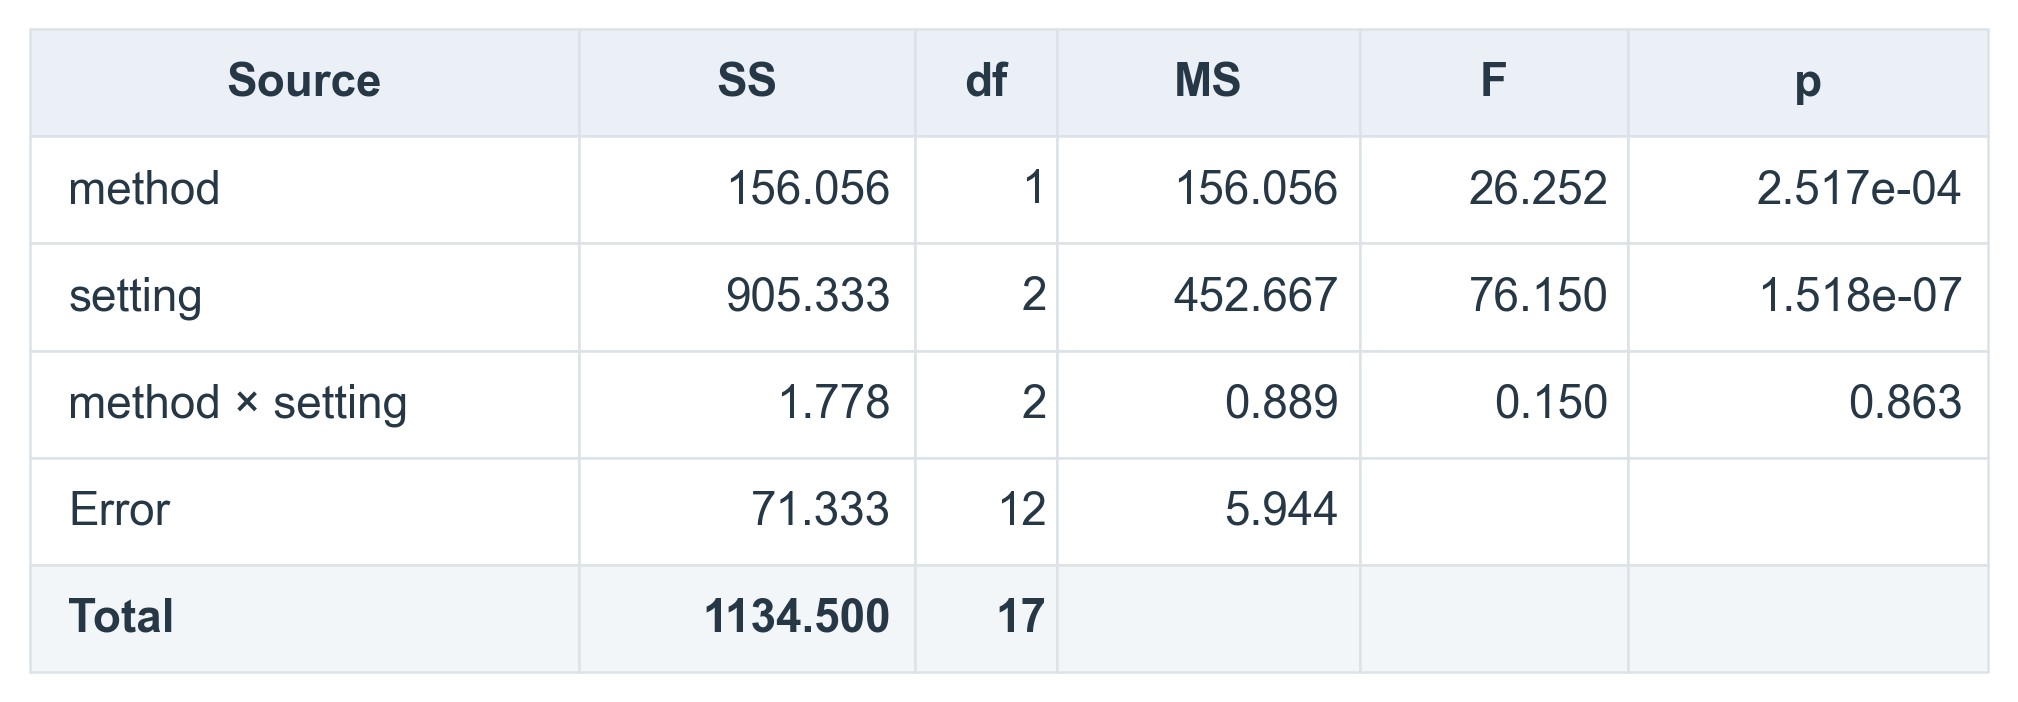

In [5]:
raw_anova = stats.anova_lm(model, typ=design['ss_type'])
term_labels = dict(zip(factor_terms, factors))
if interaction:
    term_labels[':'.join(factor_terms)] = ' × '.join(factors)
if block:
    term_labels[block_term] = f'{block} (Block)'
term_labels['Residual'] = 'Error'
anova_table = raw_anova.loc[list(term_labels)].rename(
    columns={'sum_sq': 'SS', 'mean_sq': 'MS', 'PR(>F)': 'p'}
).copy()
if 'MS' not in anova_table:
    anova_table['MS'] = anova_table['SS'] / anova_table['df']
if not np.isfinite(anova_table.drop(index='Residual')[['F', 'p']].to_numpy()).all():
    raise ValueError('ANOVA returned a non-finite effect test.')
columns = ['SS', 'df', 'MS', 'F', 'p']
anova_table = anova_table[columns]
anova_table.loc['Total'] = [total_ss, model.nobs - 1, np.nan, np.nan, np.nan]
anova_table['df'] = anova_table['df'].astype(int)
anova_table = anova_table.rename(index=term_labels).rename_axis('Source').reset_index()

def format_p(value):
    if value == 0:
        return '< 0.001'
    return f'{value:.3e}' if value < 0.001 else f'{value:.3f}'

def show_png(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format='png', bbox_inches='tight')
    display(Image(data=buffer.getvalue(), format='png'))
    plt.close(fig)

available_fonts = {font.name for font in font_manager.fontManager.ttflist}
has_hangul = any('\uac00' <= char <= '\ud7a3' for label in source_columns for char in label)
has_hangul = has_hangul or any(
    '\uac00' <= char <= '\ud7a3' for column in group_ids
    for level in fit_data[column].cat.categories for char in str(level)
)
font_order = ['Malgun Gothic', 'NanumGothic', 'Noto Sans CJK KR', 'Arial'] if has_hangul else ['Arial']
font_family = next((font for font in font_order if font in available_fonts), 'DejaVu Sans')
apply_style()
plt.rcParams['font.family'] = [font_family, 'DejaVu Sans']
table_header = '#EAF0F5'
table_total = '#F3F6F8'
formats = {'SS': '{:.3f}', 'df': '{:d}', 'MS': '{:.3f}', 'F': '{:.3f}', 'p': format_p}

display(anova_table.style.hide(axis='index').format(formats, na_rep='', escape='html')
        .set_table_attributes('class="dataframe"')
        .set_properties(subset=columns, **{'text-align': 'right', 'white-space': 'nowrap'})
        .set_properties(subset=['Source'], **{'text-align': 'left'}))

formatted = anova_table.copy()
for column, formatter in formats.items():
    format_value = formatter.format if isinstance(formatter, str) else formatter
    formatted[column] = anova_table[column].map(lambda value: '' if pd.isna(value) else format_value(value))
table_font_size = 11
text_metrics = TextToPath()

def label_width(value, weight='normal'):
    font = font_manager.FontProperties(family=plt.rcParams['font.family'],
                                       size=table_font_size, weight=weight)
    return text_metrics.get_text_width_height_descent(value, font, ismath=False)[0]

cell_padding = 0.07
widths = []
for column in formatted:
    body_widths = [label_width(value, 'bold' if i == len(formatted) - 1 else 'normal')
                   for i, value in enumerate(formatted[column])]
    text_width = max(label_width(column, 'bold'), *body_widths)
    widths.append((text_width + 12) / (1 - 2 * cell_padding))
widths = np.array(widths)
fig, ax = plt.subplots(figsize=(max(6.8, widths.sum() / (72 * 0.96)), 0.38 * (len(formatted) + 1)))
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.03, top=0.97)
ax.set_axis_off()
table = ax.table(cellText=formatted.to_numpy(), colLabels=list(formatted),
                 colWidths=widths / widths.sum(), bbox=[0, 0, 1, 1])
table.auto_set_font_size(False)
table.set_fontsize(table_font_size)
for (row, column), cell in table.get_celld().items():
    cell.set_edgecolor(COLORS['grid'])
    cell.set_linewidth(0.6)
    cell.PAD = cell_padding
    text = cell.get_text()
    text.set_color(COLORS['ink'])
    text.set_ha('right' if row > 0 and column > 0 else ('center' if row == 0 else 'left'))
    if row in (0, len(formatted)):
        text.set_fontweight('bold')
        cell.set_facecolor(table_header if row == 0 else table_total)
show_png(fig)

## 5. 주효과 및 교호작용 그래프

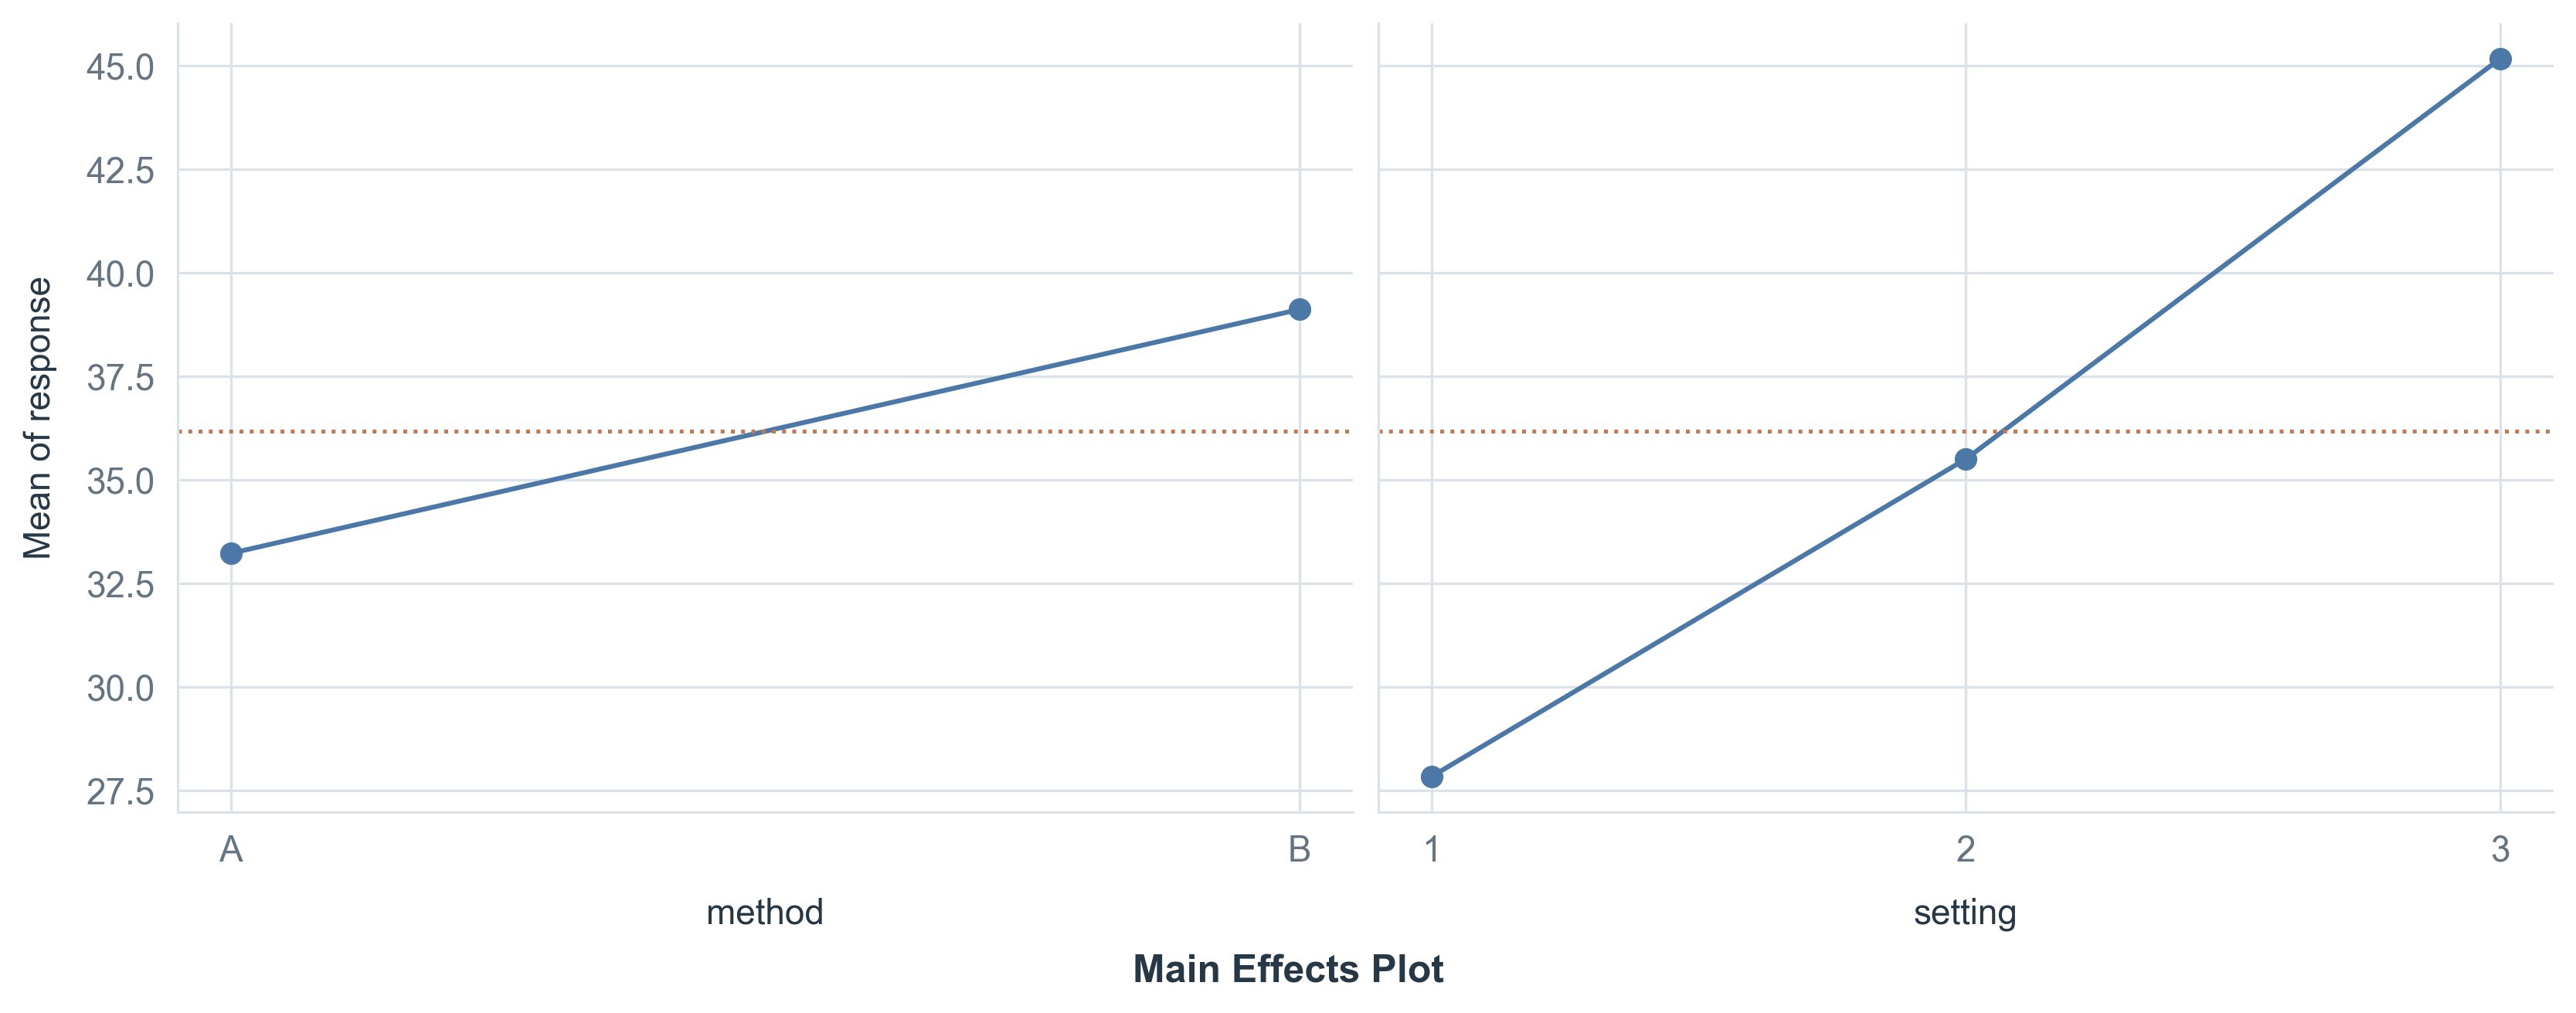

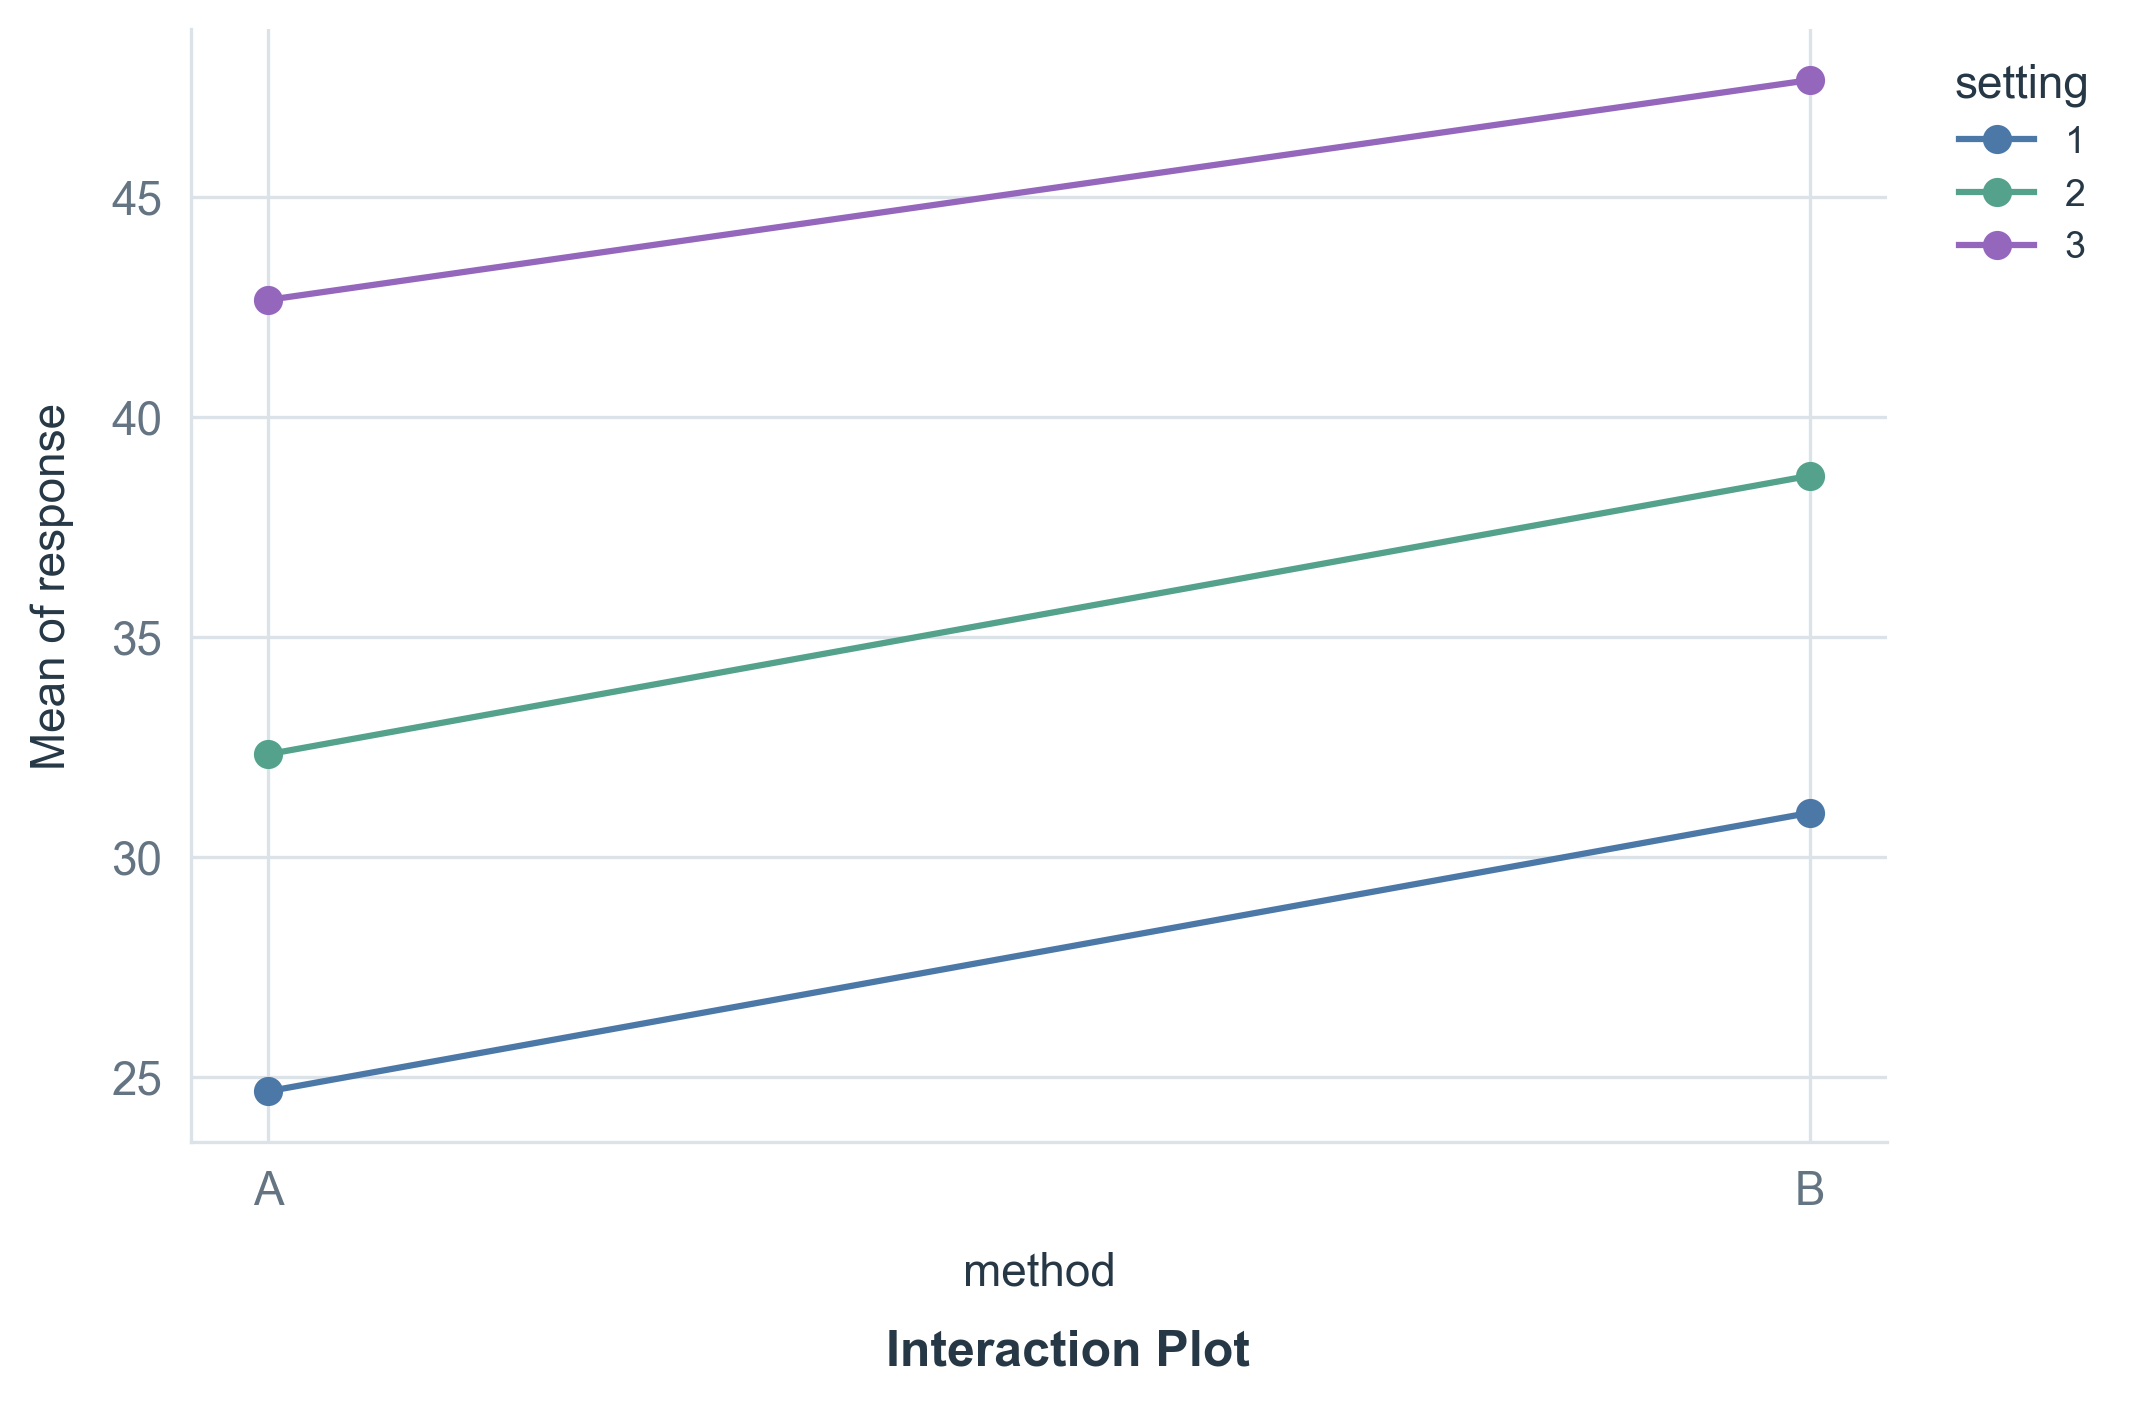

In [6]:
levels = {key: fit_data[key].cat.categories for key in factor_ids}

def label_levels(ax, key):
    labels = [str(level) for level in levels[key]]
    rotate = len(labels) > 6 or max(map(len, labels)) > 14
    ax.set_xticks(range(len(labels)), labels, rotation=35 if rotate else 0,
                  ha='right' if rotate else 'center')

fig, axes = plt.subplots(1, len(factors), squeeze=False, sharey=True,
                         figsize=(5.5 * len(factors), 4), layout='constrained')
for ax, key, factor in zip(axes.flat, factor_ids, factors):
    means = fit_data.groupby(key, observed=True)['y'].mean().reindex(levels[key])
    ax.plot(range(len(means)), means, 'o-', color=COLORS['data'])
    ax.axhline(fit_data['y'].mean(), **REFERENCE_LINE_KW)
    style_axes(ax, x_label=factor)
    label_levels(ax, key)
axes[0, 0].set_ylabel(f'Mean of {response}')
add_caption(fig, 'Main Effects Plot', y=-0.045)
show_png(fig)

if interaction:
    horizontal, series = factor_ids
    means = fit_data.groupby(factor_ids, observed=True)['y'].mean().unstack(series)
    means = means.reindex(index=levels[horizontal], columns=levels[series])
    fig, ax = plt.subplots(figsize=(7, 4.3), layout='constrained')
    ax.set_prop_cycle(color=[COLORS['data'], COLORS['secondary'], *plt.get_cmap('tab10').colors[4:]])
    for level in means:
        ax.plot(range(len(means)), means[level], 'o-', label=str(level))
    label_levels(ax, horizontal)
    style_axes(ax, x_label=factors[0], y_label=f'Mean of {response}')
    ax.legend(title=factors[1], loc='upper left', bbox_to_anchor=(1.02, 1))
    add_caption(fig, 'Interaction Plot', y=-0.045)
    show_png(fig)

## 6. 잔차 진단

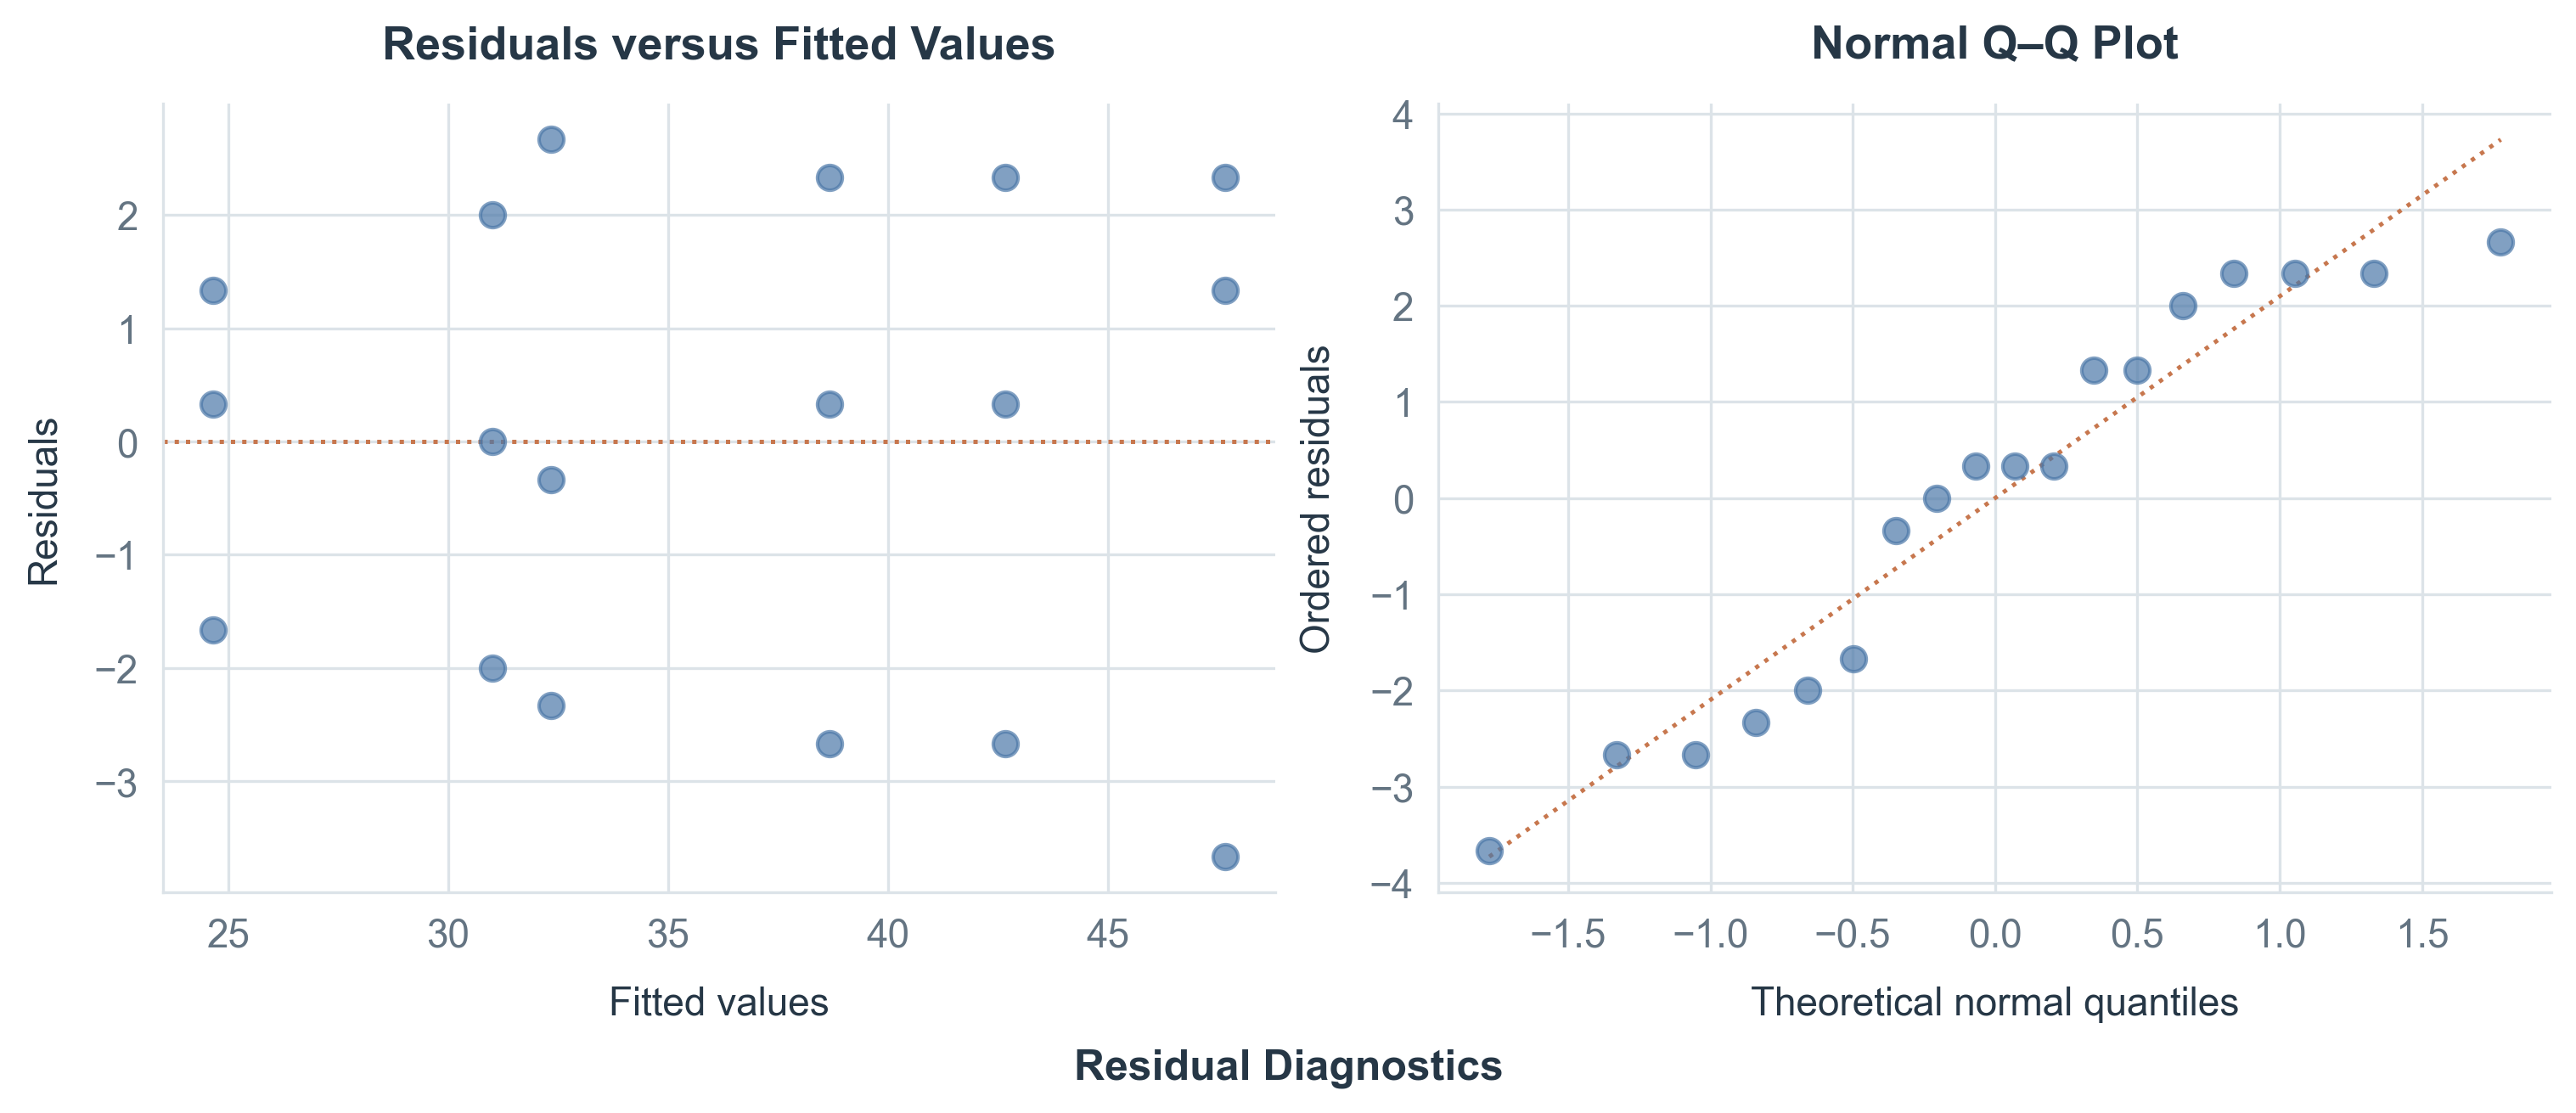

In [7]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
left.scatter(model.fittedvalues, model.resid, alpha=0.7, **SCATTER_KW)
left.axhline(0, **REFERENCE_LINE_KW)
left.set_title('Residuals versus Fitted Values')
style_axes(left, x_label='Fitted values', y_label='Residuals')
(theoretical, residuals), (slope, intercept, _) = probplot(model.resid, dist='norm')
right.scatter(theoretical, residuals, alpha=0.7, **SCATTER_KW)
right.plot(theoretical, slope * theoretical + intercept, **REFERENCE_LINE_KW)
right.set_title('Normal Q–Q Plot')
style_axes(right, x_label='Theoretical normal quantiles', y_label='Ordered residuals')
add_caption(fig, 'Residual Diagnostics', y=-0.045)
show_png(fig)